# Модели условной гетероскедастичности: GARCH для ряда ограблений

**Задача.** Проверить, есть ли в ряде кластеры волатильности (непостоянная условная дисперсия), и, если есть, описать их моделью семейства GARCH.

**Данные.** `../data/monthly-boston-armed-robberies-j.csv` — 118 месячных наблюдений числа вооружённых ограблений в Бостоне (1966–1975), Time Series Data Library.

**План.**
1. EDA: ADF-тест, ACF/PACF.
2. Подбор ARIMA по AIC, анализ остатков.
3. Тест Льюнга–Бокса на квадратах остатков ARIMA — проверка ARCH-эффекта.
4. GJR-GARCH на первых разностях ряда, проверка стандартизованных остатков.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
import statsmodels.api as sm
import statsmodels.tsa.api as smt
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model

DATA_DIR = '../data/'

In [2]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [3]:
# (вспомогательный код из учебных материалов курса)
def test_stationarity(timeseries):
    print('Результаты теста Дики-Фуллера:')
    dftest = adfuller(timeseries, autolag='AIC', result_object=False)
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic', 'p-value', '#Lags Used', 'Number of Observations Used'])
    for [key, value] in dftest[4].items():
        dfoutput['Critical Value (%s)' % key] = value
    print(dfoutput)

In [4]:
# (вспомогательный код из учебных материалов курса)
def tsplot(y, lags=None, figsize=(12, 8), style='bmh'):
    test_stationarity(y)
    if not isinstance(y, pd.Series):
        y = pd.Series(y)
    with plt.style.context(style):
        plt.figure(figsize=figsize)
        layout = (5, 1)
        ts_ax = plt.subplot2grid(layout, (0, 0), rowspan=2)
        acf_ax = plt.subplot2grid(layout, (2, 0))
        pacf_ax = plt.subplot2grid(layout, (3, 0))
        qq_ax = plt.subplot2grid(layout, (4, 0))

        y.plot(ax=ts_ax, color='blue', label='Or')
        ts_ax.set_title('Original')

        smt.graphics.plot_acf(y, lags=lags, ax=acf_ax, alpha=0.05)
        smt.graphics.plot_pacf(y, lags=lags, ax=pacf_ax, alpha=0.05)
        sm.qqplot(y, line='s', ax=qq_ax)

        plt.tight_layout()
    return

In [5]:
# временной ряд вооруженные ограбления в Бостоне
series = pd.read_csv(DATA_DIR + "monthly-boston-armed-robberies-j.csv")["Count"]

Результаты теста Дики-Фуллера:
Test Statistic                   1.001102
p-value                          0.994278
#Lags Used                      11.000000
Number of Observations Used    106.000000
Critical Value (1%)             -3.493602
Critical Value (5%)             -2.889217
Critical Value (10%)            -2.581533
dtype: float64


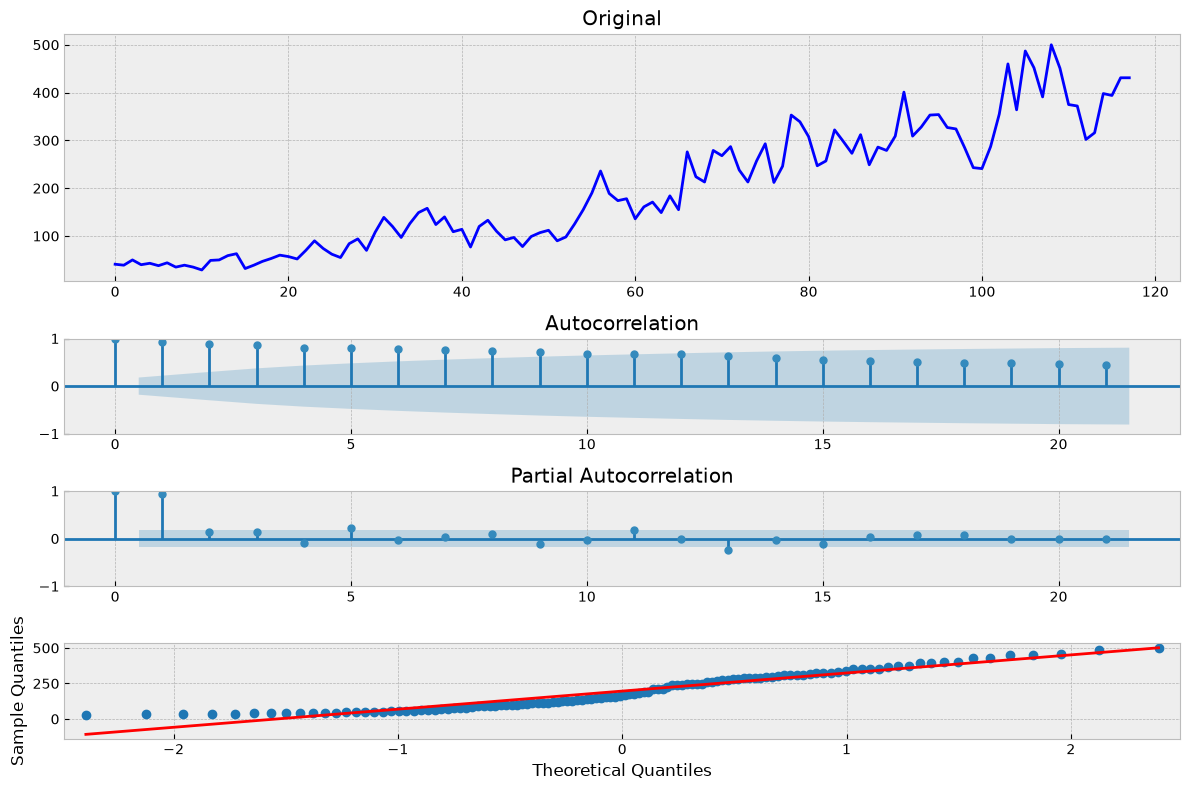

In [6]:
tsplot(series)

## Подбор ARIMA

In [7]:
# Подбор оптимальных параметров ARIMA: перебор по AIC (d = 1, т.к. исходный ряд нестационарен,
# а первая разность — стационарна; константа = дрейф)
best_aic, best_order, best_trend = np.inf, None, None
for p in range(6):
    for q in range(6):
        for trend in ['n', 't']:
            try:
                tmp = ARIMA(series, order=(p, 1, q), trend=trend).fit()
            except Exception:
                continue
            if tmp.aic < best_aic:
                best_aic, best_order, best_trend = tmp.aic, (p, 1, q), trend
print(f'Лучшая модель: ARIMA{best_order}, trend={best_trend!r}, AIC={best_aic:.3f}')

Лучшая модель: ARIMA(3, 1, 3), trend='t', AIC=1179.078


In [8]:
mdl = ARIMA(series, order=best_order, trend=best_trend).fit()
print(mdl.summary().tables[1])
# При d=1 первый остаток равен самому первому наблюдению ряда — исключаем его из диагностики
resid = mdl.resid.iloc[1:]

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             3.4762      0.253     13.718      0.000       2.980       3.973
ar.L1         -0.5478      0.091     -5.995      0.000      -0.727      -0.369
ar.L2         -0.2006      0.115     -1.740      0.082      -0.427       0.025
ar.L3          0.6401      0.097      6.616      0.000       0.450       0.830
ma.L1          0.1254      0.572      0.219      0.827      -0.996       1.247
ma.L2         -0.1348      0.639     -0.211      0.833      -1.388       1.118
ma.L3         -0.9867      0.562     -1.755      0.079      -2.088       0.115
sigma2      1145.2826    667.261      1.716      0.086    -162.525    2453.091


In [9]:
tsplot(resid)

Результаты теста Дики-Фуллера:
Test Statistic                -1.015282e+01
p-value                        7.869020e-18
#Lags Used                     0.000000e+00
Number of Observations Used    1.160000e+02
Critical Value (1%)           -3.488022e+00
Critical Value (5%)           -2.886797e+00
Critical Value (10%)          -2.580241e+00
dtype: float64


In [10]:
# Тест Льюнга-Бокса на квадратах остатков (проверка на волатильность)
from statsmodels.stats.diagnostic import acorr_ljungbox

# Квадраты остатков для проверки на гетероскедастичность (ARCH-эффект).
# Для устойчивости вывода проверяем две модели среднего: выбранную перебором по AIC
# и более простую ARIMA(0,1,2), которую в первой версии работы выбрал stepwise-поиск pmdarima.
resid_012 = ARIMA(series, order=(0, 1, 2)).fit().resid.iloc[1:]

for title, r in [(f'ARIMA{best_order}, trend={best_trend!r}', resid), ('ARIMA(0, 1, 2)', resid_012)]:
    print(f"=== {title} ===")
    residuals_sq = r ** 2
    for lag in [10, 20]:
        lb_test = acorr_ljungbox(residuals_sq, lags=[lag], return_df=True)
        p_value = lb_test['lb_pvalue'].iloc[0]
        stat = lb_test['lb_stat'].iloc[0]
        verdict = 'есть значимая автокорреляция квадратов остатков' if p_value < 0.05 else 'значимой автокорреляции нет'
        print(f"Лаг {lag}: LB = {stat:.4f}, p-value = {p_value:.4f} -> {verdict}")
    print("-" * 50)

=== ARIMA(3, 1, 3), trend='t' ===


Лаг 10: LB = 18.0798, p-value = 0.0536 -> значимой автокорреляции нет
Лаг 20: LB = 28.0608, p-value = 0.1080 -> значимой автокорреляции нет
--------------------------------------------------
=== ARIMA(0, 1, 2) ===
Лаг 10: LB = 22.8538, p-value = 0.0113 -> есть значимая автокорреляция квадратов остатков
Лаг 20: LB = 32.5488, p-value = 0.0378 -> есть значимая автокорреляция квадратов остатков
--------------------------------------------------


Модель среднего, выбранная полным перебором по AIC, — ARIMA(3,1,3) с дрейфом (AIC = 1179.08); у неё незначимы MA-коэффициенты, что указывает на избыточную сложность. Для неё тест Льюнга–Бокса на квадратах остатков **не отвергает** гипотезу об отсутствии автокорреляции (p-value 0.054 на лаге 10 и 0.108 на лаге 20). Для более простой ARIMA(0,1,2) (её выбрал stepwise-поиск `pmdarima` в первой версии работы) ARCH-эффект значим: p-value 0.011 и 0.038.

Вывод: признаки непостоянной условной дисперсии есть, но они пограничные и зависят от модели среднего. Применение GARCH обосновано скорее визуально (дисперсия растёт вместе с уровнем ряда), чем строго статистически.

## Применим GARCH

In [11]:
# Приведем исходный ряд к стационарности
series = series.diff()
series = series.dropna()

In [12]:
p_ = 0
o_ = 1
q_ = 2

am = arch_model(series, vol='GARCH', p=p_, o=o_, q=q_, dist='Studentst')
res = am.fit(update_freq=5, disp='off')
print(res.summary())

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                        Count   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -577.901
Distribution:      Standardized Student's t   AIC:                           1167.80
Method:                  Maximum Likelihood   BIC:                           1184.37
                                              No. Observations:                  117
Date:                      Sat, Nov 21 2026   Df Residuals:                      116
Time:                              00:11:17   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             3

In [13]:
tsplot(res.resid)

Результаты теста Дики-Фуллера:
Test Statistic                -7.428564e+00
p-value                        6.450795e-11
#Lags Used                     1.000000e+01
Number of Observations Used    1.060000e+02
Critical Value (1%)           -3.493602e+00
Critical Value (5%)           -2.889217e+00
Critical Value (10%)          -2.581533e+00
dtype: float64


In [14]:
# Проверка: остался ли ARCH-эффект в стандартизованных остатках GARCH
std_resid = res.std_resid.dropna()
for lag in [10, 20]:
    lb = acorr_ljungbox(std_resid ** 2, lags=[lag], return_df=True)
    print(f"Квадраты стандартизованных остатков, лаг {lag}: LB = {lb['lb_stat'].iloc[0]:.4f}, "
          f"p-value = {lb['lb_pvalue'].iloc[0]:.4f}")

Квадраты стандартизованных остатков, лаг 10: LB = 11.6906, p-value = 0.3063
Квадраты стандартизованных остатков, лаг 20: LB = 19.9688, p-value = 0.4599


## Обобщающий вывод о применимости GARCH

GJR-GARCH(p=0, o=1, q=2) с t-распределением на первых разностях ряда:

- **Асимметрия:** коэффициент gamma[1] = 0.10, p-value = 0.048 — значим на грани уровня 0.05. Отрицательные шоки (снижение числа ограблений) увеличивают последующую волатильность сильнее, чем положительные — аналог «эффекта рычага» из финансовых рядов.
- **Высокая инерция волатильности:** beta[1] = 0.95 (p-value = 0.012); периоды высокой волатильности сохраняются долго. Сумма gamma/2 + beta ≈ 1 — процесс близок к интегрированному (IGARCH), а стандартная ошибка beta[1] велика (0.378), поэтому оценка неустойчива.
- **Упрощение модели:** beta[2] = 0 (p-value = 1.0), так что второй лаг лишний; разумно сравнить с GARCH(1,1) / GJR-GARCH(1,1,1) по AIC/BIC.
- **Распределение:** число степеней свободы nu ≈ 35 (незначимо) — распределение шоков близко к нормальному, t-распределение здесь почти ничего не даёт.
- **Остатки:** в квадратах стандартизованных остатков GARCH значимой автокорреляции нет (Льюнг–Бокс: p-value 0.31 на лаге 10 и 0.46 на лаге 20), то есть модель описывает имеющуюся кластеризацию волатильности.

Итого: GJR-GARCH формально применим и снимает остаточную гетероскедастичность, но исходный ARCH-эффект пограничный, а ряд короткий (117 разностей), поэтому выводы о структуре волатильности стоит считать предварительными.